# Credit Risk Classification

Predicting loan default probability (`loan_status`: `0` = paid, `1` = default) using demographic and financial borrower data.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

sns.set_style("whitegrid")

## 1. Data Loading & Initial Inspection

In [2]:
DATA_PATH = "Kredit_Risk_Model/data/credit_risk_dataset.csv"
DATA_PATH = "../data/credit_risk_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.info()

missing = df.isnull().sum()
print("\nMissing values:")
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB

Missing values:
person_emp_length     895
loa

## 2. Data Cleaning

- Remove 165 duplicate rows.
- Filter out unrealistic outliers (`person_age > 90` and `person_emp_length > 60`), while keeping `NaN` values in `person_emp_length` to be imputed later inside the pipeline.

In [4]:
df_clean = df.drop_duplicates().copy()

valid_mask = (df_clean["person_age"] <= 90) & (
    df_clean["person_emp_length"].isna() | (df_clean["person_emp_length"] <= 60)
)
df_clean = df_clean[valid_mask].reset_index(drop=True)

print("Cleaned shape:", df_clean.shape)
print("Removed rows:", len(df) - len(df_clean))
print("Max age:", df_clean["person_age"].max())
print("Max employment length:", df_clean["person_emp_length"].max())

print("\nTarget distribution (%):")
print((df_clean["loan_status"].value_counts(normalize=True) * 100).round(2))

Cleaned shape: (32408, 12)
Removed rows: 173
Max age: 84
Max employment length: 41.0

Target distribution (%):
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64


## 3. Exploratory Data Analysis

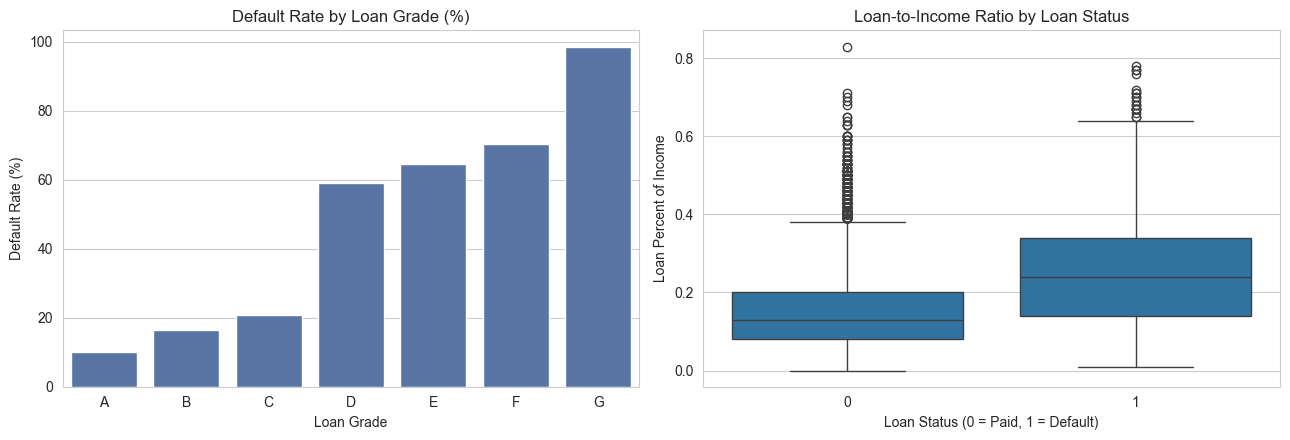

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

grade_order = sorted(df_clean["loan_grade"].unique())
grade_default = (
    df_clean.groupby("loan_grade")["loan_status"].mean().reindex(grade_order) * 100
)
sns.barplot(x=grade_default.index, y=grade_default.values, ax=axes[0], color="#4C72B0")
axes[0].set_title("Default Rate by Loan Grade (%)")
axes[0].set_xlabel("Loan Grade")
axes[0].set_ylabel("Default Rate (%)")

sns.boxplot(data=df_clean, x="loan_status", y="loan_percent_income", ax=axes[1])
axes[1].set_title("Loan-to-Income Ratio by Loan Status")
axes[1].set_xlabel("Loan Status (0 = Paid, 1 = Default)")
axes[1].set_ylabel("Loan Percent of Income")

plt.tight_layout()
plt.show()

## 4. Feature Engineering & Train/Test Split

Added three domain-specific financial ratios:
- `annual_interest_payment`: estimated yearly interest cost (`loan_amnt * loan_int_rate / 100`)
- `interest_to_income`: ratio of annual interest payment to borrower annual income
- `emp_to_age_ratio`: employment length relative to borrower age

In [6]:
df_clean["annual_interest_payment"] = df_clean["loan_amnt"] * (df_clean["loan_int_rate"] / 100)
df_clean["interest_to_income"] = df_clean["annual_interest_payment"] / df_clean["person_income"]
df_clean["emp_to_age_ratio"] = df_clean["person_emp_length"] / df_clean["person_age"]

numeric_cols = df_clean.select_dtypes(include="number").columns
print("Correlation with loan_status:")
print(df_clean[numeric_cols].corr()["loan_status"].sort_values(ascending=False).round(3))

X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nX_train: {X_train.shape} | Default rate: {y_train.mean() * 100:.2f}%")
print(f"X_test:  {X_test.shape}  | Default rate: {y_test.mean() * 100:.2f}%")

Correlation with loan_status:
loan_status                   1.000
interest_to_income            0.460
loan_percent_income           0.380
loan_int_rate                 0.336
annual_interest_payment       0.216
loan_amnt                     0.106
cb_person_cred_hist_length   -0.016
person_age                   -0.022
person_emp_length            -0.086
emp_to_age_ratio             -0.086
person_income                -0.169
Name: loan_status, dtype: float64

X_train: (25926, 14) | Default rate: 21.87%
X_test:  (6482, 14)  | Default rate: 21.88%


## 5. Preprocessing Pipeline & Model Comparison

In [7]:
num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(include="object").columns.tolist()

num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features),
])

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=200, max_depth=4, random_state=42),
}

results = []
trained_models = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", clf),
    ])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 1),
        "F1-score": round(f1_score(y_test, y_pred), 3),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 3),
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

C:\Users\user\AppData\Local\Temp\ipykernel_23312\2753849701.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X.select_dtypes(include="object").columns.tolist()


             Model  Accuracy (%)  F1-score  ROC-AUC
LogisticRegression          86.6     0.649    0.871
      RandomForest          93.3     0.824    0.929
  GradientBoosting          93.8     0.839    0.948


## 6. Best Model Evaluation & Inference Example

Classification Report (GradientBoosting):
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5064
           1       0.97      0.74      0.84      1418

    accuracy                           0.94      6482
   macro avg       0.95      0.87      0.90      6482
weighted avg       0.94      0.94      0.93      6482

Confusion Matrix:
[[5028   36]
 [ 368 1050]]


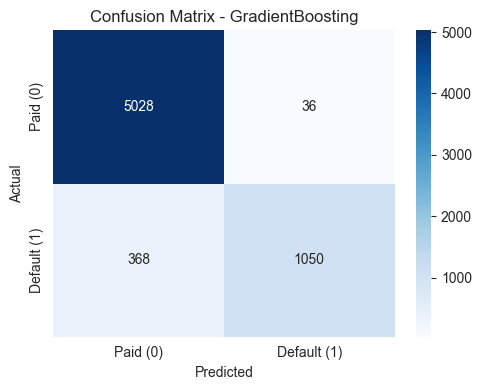

In [8]:
best_model = trained_models["GradientBoosting"]
y_pred_best = best_model.predict(X_test)

print("Classification Report (GradientBoosting):")
print(classification_report(y_test, y_pred_best))

cm = confusion_matrix(y_test, y_pred_best)
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Paid (0)", "Default (1)"],
    yticklabels=["Paid (0)", "Default (1)"],
)
plt.title("Confusion Matrix - GradientBoosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [9]:
os.makedirs("../models", exist_ok=True)
MODEL_PATH = "../models/credit_risk_model.pkl"
joblib.dump(best_model, MODEL_PATH)
print(f"Saved model to {MODEL_PATH}")


def predict_default_risk(model, applicant_data):
    df_input = pd.DataFrame([applicant_data])
    df_input["loan_percent_income"] = round(
        df_input["loan_amnt"] / df_input["person_income"], 2
    )
    df_input["annual_interest_payment"] = df_input["loan_amnt"] * (
        df_input["loan_int_rate"] / 100
    )
    df_input["interest_to_income"] = (
        df_input["annual_interest_payment"] / df_input["person_income"]
    )
    df_input["emp_to_age_ratio"] = (
        df_input["person_emp_length"] / df_input["person_age"]
    )
    prob = model.predict_proba(df_input)[0][1] * 100
    return round(prob, 1)


sample_applicant = {
    "person_age": 30,
    "person_income": 24000,
    "person_home_ownership": "OWN",
    "person_emp_length": 9.0,
    "loan_intent": "PERSONAL",
    "loan_grade": "B",
    "loan_amnt": 5000,
    "loan_int_rate": 10.5,
    "cb_person_default_on_file": "N",
    "cb_person_cred_hist_length": 4,
}

risk_pct = predict_default_risk(best_model, sample_applicant)
print(f"Default probability: {risk_pct}%")
print("Decision:", "APPROVED" if risk_pct < 30 else "REJECTED")

Saved model to ../models/credit_risk_model.pkl
Default probability: 0.9%
Decision: APPROVED
